# Report notebook: final model, parameter count, accuracy and all plots

NYU Tandon Deep Learning F26, Project 1 (CIFAR-10 ResNet, <= 5M parameters).
Team: Rahim Askarov (ra3716), Philip Vetsas (pmv264).

This notebook

1. counts the parameters of every architecture we tried (and checks the 5M budget),
2. loads the **final model** (`KEEP/F2s1.pt`), re-runs our test-time augmentation on the 2000 Kaggle
   test images and checks that it reproduces the submitted CSV label for label,
3. re-computes the **validation accuracy** of our best held-out model (`ckpts/A4.pt`) on the fixed
   5000-image validation split,
4. makes every figure in the report from the per-run logs in `runs/<run>/log.csv`.

Steps 2 and 3 need the checkpoints and data (not in git, see README); they are skipped if missing.
Steps 1 and 4 only need the repo.

In [1]:
import json, os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from models import ARCHS, TEACHER_ARCHS, build_model, count_params, load_model

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .3})
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: cpu


## 1. Parameter counts (budget: 5,000,000 trainable parameters)

In [2]:
rows = []
for name, cfg in {**ARCHS, **TEACHER_ARCHS}.items():
    if name in ("wrn_16_1", "pyramid_20_24"):        # tiny smoke-test models
        continue
    n = count_params(build_model(cfg))
    role = "student" if name in ARCHS else ("2-model ensemble member" if name == "wrn_40_2" else "teacher")
    rows.append((name, role, n, "yes" if n <= 5_000_000 else "NO (teacher, training only)"))
pd.DataFrame(rows, columns=["arch", "role", "params", "<= 5M"]).set_index("arch")

,role,params,<= 5M
arch,,,
r3_64_3-5-3,student,4918602,yes
r3_80_2-3-3,student,4880474,yes
r3_96_2-2-2,student,4902506,yes
r4_64_3-3-2-1,student,4890442,yes
r3_40_8-8-8,student,4722610,yes
wrn_28_10,teacher,36479194,"NO (teacher, training only)"
pyramid_110_270,teacher,28485477,"NO (teacher, training only)"
wrn_40_2,2-model ensemble member,2243546,yes


In [3]:
from torchsummary import summary   # the tool the assignment suggests
final_arch = "r3_80_2-3-3"
summary(build_model(ARCHS[final_arch]), (3, 32, 32), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 80, 32, 32]           2,160
       BatchNorm2d-2           [-1, 80, 32, 32]             160
              ReLU-3           [-1, 80, 32, 32]               0
            Conv2d-4           [-1, 80, 32, 32]          57,600
       BatchNorm2d-5           [-1, 80, 32, 32]             160
            Conv2d-6           [-1, 80, 32, 32]          57,600
       BatchNorm2d-7           [-1, 80, 32, 32]             160
          Identity-8           [-1, 80, 32, 32]               0
          Identity-9           [-1, 80, 32, 32]               0
         Identity-10           [-1, 80, 32, 32]               0
       BasicBlock-11           [-1, 80, 32, 32]               0
           Conv2d-12           [-1, 80, 32, 32]          57,600
      BatchNorm2d-13           [-1, 80, 32, 32]             160
           Conv2d-14           [-1, 80,

## 2. Final model: reproduce the Kaggle submission

In [4]:
from data import load_test
from tta import view_probs, combine

FINAL = "KEEP/F2s1.pt"
if os.path.exists(FINAL) and os.path.exists("data/test_images"):
    model, ck = load_model(FINAL)                 # EMA weights
    model = model.to(device)
    n_params = count_params(model)
    print("arch:", ck["arch"], "| epochs:", ck["epoch"], "| trained on all 50k images (val_size =", ck["args"]["val_size"], ")")
    x_test, ids = load_test()
    t = time.time()
    probs = view_probs(model, x_test, device)    # (10 views, 2000, 10) softmax
    pred = combine(probs, "5crop").argmax(1)     # average the 10 views
    print(f"TTA inference on {len(x_test)} test images: {time.time() - t:.0f} s")
    ref = pd.read_csv("KEEP/submission_F2s1_tta5.csv")
    assert (ref["id"].values == ids).all()
    print("labels different from the submitted CSV:", int((ref["label"].values != pred).sum()), "/", len(pred))
else:
    n_params = count_params(build_model(ARCHS[final_arch]))
    print("checkpoint or test data missing -> skipped (see README, section 4)")

arch: r3_80_2-3-3 | epochs: 1200 | trained on all 50k images (val_size = 0 )


TTA inference on 2000 test images: 262 s
labels different from the submitted CSV: 0 / 2000


## 3. Validation accuracy (fixed 5000-image holdout, same split for every model)

In [5]:
from data import load_train, train_val_split

VAL_MODEL = "ckpts/A4.pt"   # same recipe as the final model, 600 epochs, 5000 images held out
if os.path.exists(VAL_MODEL) and os.path.exists("data/train_cache.npz"):
    x, y = load_train()
    _, _, x_val, y_val = train_val_split(x, y, val_size=5000, seed=0)
    m, _ = load_model(VAL_MODEL)
    pv = view_probs(m.to(device), x_val, device)
    acc_plain = (pv[0].argmax(1) == y_val).mean()
    acc_flip = (combine(pv, "flip").argmax(1) == y_val).mean()
    acc_tta = (combine(pv, "5crop").argmax(1) == y_val).mean()
    print(f"A4 val accuracy: no TTA {acc_plain:.2%} | flip {acc_flip:.2%} | 10-view TTA {acc_tta:.2%}")
else:
    acc_tta = 0.9792
    print("checkpoint missing -> using the logged value 97.92%")

A4 val accuracy: no TTA 97.72% | flip 97.84% | 10-view TTA 97.92%


## 4. Training curves

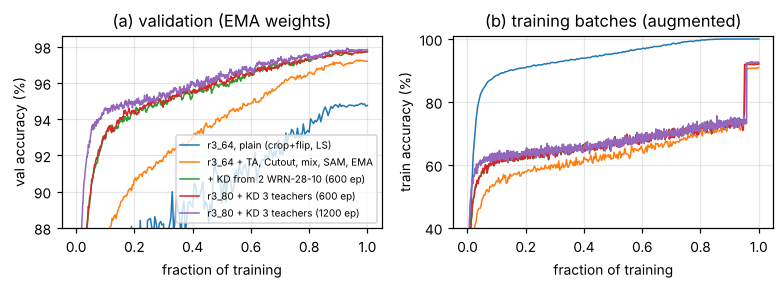

In [6]:
def log(run):
    return pd.read_csv(f"runs/{run}/log.csv")

curves = [
    ("student_baseline", "r3_64, plain (crop+flip, LS)", "val_acc"),
    ("student_tricks_300", "r3_64 + TA, Cutout, mix, SAM, EMA", "val_acc_ema"),
    ("kd_r3_64_2t_600", "+ KD from 2 WRN-28-10 (600 ep)", "val_acc_ema"),
    ("A4_r3_80_600", "r3_80 + KD 3 teachers (600 ep)", "val_acc_ema"),
    ("V2_r3_80_1200", "r3_80 + KD 3 teachers (1200 ep)", "val_acc_ema"),
]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.7))
for run, label, col in curves:
    d = log(run)
    frac = d["epoch"] / d["epoch"].max()
    ax[0].plot(frac, 100 * d[col], lw=1, label=label)
    ax[1].plot(frac, 100 * d["train_acc"], lw=1, label=label)
ax[0].set(ylim=(88, 98.6), xlabel="fraction of training", ylabel="val accuracy (%)", title="(a) validation (EMA weights)")
ax[1].set(ylim=(40, 101), xlabel="fraction of training", ylabel="train accuracy (%)", title="(b) training batches (augmented)")
ax[0].legend(fontsize=6.5, loc="lower right")
fig.tight_layout(); fig.savefig("figures/curves.pdf"); plt.show()

## 5. What each step added (validation, flip TTA unless noted)

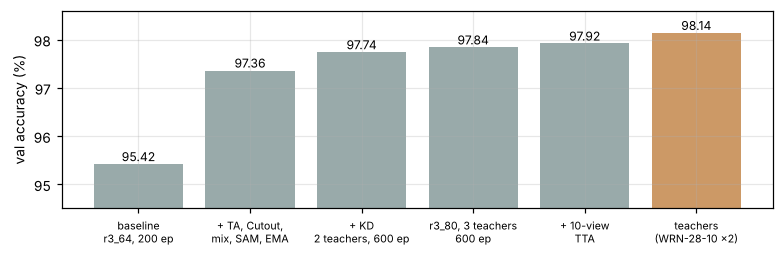

In [7]:
steps = [("baseline\nr3_64, 200 ep", 95.42), ("+ TA, Cutout,\nmix, SAM, EMA", 97.36),
         ("+ KD\n2 teachers, 600 ep", 97.74), ("r3_80, 3 teachers\n600 ep", 97.84),
         ("+ 10-view\nTTA", 97.92), ("teachers\n(WRN-28-10 x2)", 98.14)]
fig, ax = plt.subplots(figsize=(7.2, 2.4))
cols = ["#9aa"] * 5 + ["#c96"]
b = ax.bar(range(len(steps)), [v for _, v in steps], color=cols)
ax.bar_label(b, fmt="%.2f", fontsize=8)
ax.set_xticks(range(len(steps)), [s for s, _ in steps], fontsize=7)
ax.set(ylim=(94.5, 98.6), ylabel="val accuracy (%)")
fig.tight_layout(); fig.savefig("figures/steps.pdf"); plt.show()

## 6. Architecture sweep (300 epochs, same recipe, KD from 3 teachers)

In [8]:
sweep = []
for run in sorted(glob.glob("runs/A_sweep_kd3t_300_*")):
    r = run.split("/")[-1]
    if os.path.exists(f"{run}/results.json"):
        j = json.load(open(f"{run}/results.json"))
        sweep.append((j["arch"], j["params"], 100 * j["val_acc_ema_tta"]))
pd.DataFrame(sweep, columns=["arch", "params", "val % (EMA, flip TTA)"]).sort_values("val % (EMA, flip TTA)", ascending=False)

,arch,params,"val % (EMA, flip TTA)"
1,r3_80_2-3-3,4880474,97.62
2,r3_96_2-2-2,4902506,97.42
0,r3_64_3-5-3,4918602,97.38


## 7. Controlled experiments (paired against a matched control on the same 5000 val images)

Numbers are the difference in correctly classified validation images (5 images = 0.1 pt), 10-view TTA,
EMA weights, from `EXPERIMENTS.md` (computed with `scripts/tta_eval.py compare`). Two groups:
60-epoch continuations of A4 (control: SAM continuation) and fresh 300-epoch runs (control: V300_ctrl).

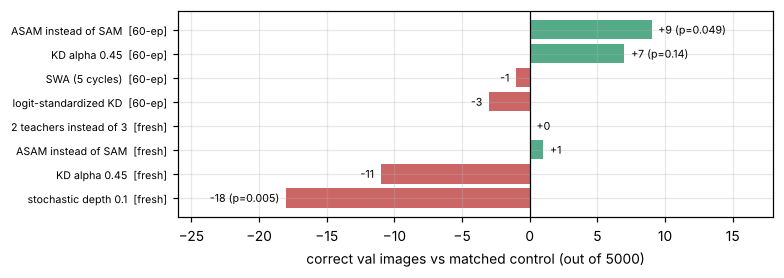

In [9]:
exp = [  # (name, images vs control, p-value of exact sign test or None, group)
    ("ASAM instead of SAM", +9, .049, "60-ep continuation of A4"),
    ("KD alpha 0.45", +7, .14, "60-ep continuation of A4"),
    ("SWA (5 cycles)", -1, None, "60-ep continuation of A4"),
    ("logit-standardized KD", -3, None, "60-ep continuation of A4"),
    ("2 teachers instead of 3", 0, None, "fresh 300 ep"),
    ("ASAM instead of SAM", +1, None, "fresh 300 ep"),
    ("KD alpha 0.45", -11, None, "fresh 300 ep"),
    ("stochastic depth 0.1", -18, .005, "fresh 300 ep"),
]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
names = [f"{n}  [{g.split()[0]}]" for n, _, _, g in exp]
vals = [v for _, v, _, _ in exp]
ax.barh(range(len(exp)), vals, color=["#5a8" if v > 0 else "#c66" for v in vals])
for i, (_, v, p, _) in enumerate(exp):
    ax.text(v + (0.5 if v >= 0 else -0.5), i, f"{v:+d}" + (f" (p={p})" if p else ""),
            va="center", ha="left" if v >= 0 else "right", fontsize=7)
ax.set_yticks(range(len(exp)), names, fontsize=7); ax.invert_yaxis()
ax.axvline(0, color="k", lw=.8); ax.set_xlim(-26, 18)
ax.set_xlabel("correct val images vs matched control (out of 5000)")
fig.tight_layout(); fig.savefig("figures/ablations.pdf"); plt.show()

## 8. Final result

In [10]:
print("Final model           :", final_arch, "(ResNet, 3 stages, channels 80/160/256, blocks 2/3/3)")
print(f"Trainable parameters  : {n_params:,}  (budget 5,000,000)")
print(f"Validation accuracy   : {acc_tta:.2%}  (A4: same recipe, 600 ep, 5000 held-out images, 10-view TTA)")
print("Kaggle test accuracy  : 0.911  (public leaderboard, F2s1: 1200 ep on all 50k images, 10-view TTA)")

Final model           : r3_80_2-3-3 (ResNet, 3 stages, channels 80/160/256, blocks 2/3/3)
Trainable parameters  : 4,880,474  (budget 5,000,000)
Validation accuracy   : 97.92%  (A4: same recipe, 600 ep, 5000 held-out images, 10-view TTA)
Kaggle test accuracy  : 0.911  (public leaderboard, F2s1: 1200 ep on all 50k images, 10-view TTA)
